# Detector de dents impactades amb Faster R-CNN

Objectiu: passar de classificar tota l'ortopantomografia a predir directament les posicions de les dents impactades.

El model aprendrà una única classe clínica:

- `0`: background, reservat internament pel detector.
- `1`: dent impactada.

Les anotacions DENTEX tenen les boxes en format `[x, y, amplada, altura]`. Faster R-CNN necessita `[x_min, y_min, x_max, y_max]`, així que el dataset farà la conversió.

Aquest és un primer baseline: sense augmentacions, una sola classe i mètriques senzilles a IoU 0.5.

In [1]:
from pathlib import Path
from collections import defaultdict
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


In [2]:
data_dir = Path("data/raw/dentex")

train_images_dir = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "xrays"
)

val_images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

train_json_path = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "train_quadrant_enumeration_disease.json"
)

val_json_path = data_dir / "validation_triple.json"

with open(train_json_path, "r") as file:
    train_data = json.load(file)

with open(val_json_path, "r") as file:
    val_data = json.load(file)


def find_diagnosis_id(data, diagnosis_name):
    """
    Busca l'id real al JSON en lloc de suposar que impacted sempre és 0.
    """
    diagnosis_name = diagnosis_name.lower()

    for category in data["categories_3"]:
        if diagnosis_name in category["name"].lower():
            return category["id"]

    raise ValueError(
        f"No s'ha trobat el diagnòstic: {diagnosis_name}"
    )


train_impacted_id = find_diagnosis_id(train_data, "impacted")
val_impacted_id = find_diagnosis_id(val_data, "impacted")

assert train_impacted_id == val_impacted_id
impacted_category_id = train_impacted_id

print("Train images:", len(train_data["images"]))
print("Validation images:", len(val_data["images"]))
print("ID de la categoria impacted:", impacted_category_id)
print("Categories de diagnòstic:", train_data["categories_3"])



Train images: 705
Validation images: 50
ID de la categoria impacted: 0
Categories de diagnòstic: [{'id': 0, 'name': 'Impacted', 'supercategory': 'Impacted'}, {'id': 1, 'name': 'Caries', 'supercategory': 'Caries'}, {'id': 2, 'name': 'Periapical Lesion', 'supercategory': 'Periapical Lesion'}, {'id': 3, 'name': 'Deep Caries', 'supercategory': 'Deep Caries'}]


In [3]:
class DentexImpactedDetectionDataset(Dataset):
    def __init__(
        self,
        data,
        images_dir,
        impacted_category_id
    ):
        self.images = data["images"]
        self.images_dir = Path(images_dir)
        self.impacted_category_id = impacted_category_id

        # Només guardem les anotacions de la categoria impacted
        # que hem identificat directament des de categories_3.
        self.impacted_annotations = defaultdict(list)

        for annotation in data["annotations"]:
            if (
                annotation["category_id_3"]
                == self.impacted_category_id
            ):
                self.impacted_annotations[
                    annotation["image_id"]
                ].append(annotation)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_id = image_info["id"]

        image_path = self.images_dir / image_info["file_name"]
        pil_image = Image.open(image_path).convert("RGB")

        image_width, image_height = pil_image.size

        # Tensor float en rang [0, 1].
        # Faster R-CNN farà internament la normalització i el resize.
        image = TF.pil_to_tensor(pil_image).float() / 255.0

        boxes = []

        for annotation in self.impacted_annotations.get(image_id, []):
            x, y, width, height = map(float, annotation["bbox"])

            # Format DENTEX xywh -> format Faster R-CNN xyxy.
            x_min = max(0.0, x)
            y_min = max(0.0, y)
            x_max = min(float(image_width), x + width)
            y_max = min(float(image_height), y + height)

            # Ignorem boxes degenerades, si n'hi hagués alguna.
            if x_max > x_min and y_max > y_min:
                boxes.append([x_min, y_min, x_max, y_max])

        if boxes:
            boxes = torch.tensor(boxes, dtype=torch.float32)
        else:
            boxes = torch.zeros((0, 4), dtype=torch.float32)

        # Totes les boxes que hem conservat són classe 1: impacted.
        labels = torch.ones(
            (boxes.shape[0],),
            dtype=torch.int64
        )

        area = (
            (boxes[:, 2] - boxes[:, 0])
            * (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id]),
            "area": area,
            "iscrowd": torch.zeros(
                (boxes.shape[0],),
                dtype=torch.int64
            )
        }

        return image, target

    def file_name(self, index):
        return self.images[index]["file_name"]



In [4]:
train_dataset = DentexImpactedDetectionDataset(
    train_data,
    train_images_dir,
    impacted_category_id
)

val_dataset = DentexImpactedDetectionDataset(
    val_data,
    val_images_dir,
    impacted_category_id
)


def dataset_summary(dataset):
    boxes_per_image = [
        len(dataset.impacted_annotations.get(info["id"], []))
        for info in dataset.images
    ]

    return {
        "images": len(dataset),
        "positive_images": sum(n > 0 for n in boxes_per_image),
        "negative_images": sum(n == 0 for n in boxes_per_image),
        "impacted_boxes": sum(boxes_per_image)
    }


display(pd.DataFrame([
    {"split": "train", **dataset_summary(train_dataset)},
    {"split": "validation", **dataset_summary(val_dataset)}
]))

# Comprovacions bàsiques.
image, target = train_dataset[0]
print("Forma de la imatge:", image.shape)
print("Forma de boxes:", target["boxes"].shape)
print("Labels:", target["labels"])



,split,images,positive_images,negative_images,impacted_boxes
0,train,705,254,451,604
1,validation,50,16,34,40


Forma de la imatge: torch.Size([3, 1316, 2744])
Forma de boxes: torch.Size([2, 4])
Labels: tensor([1, 1])


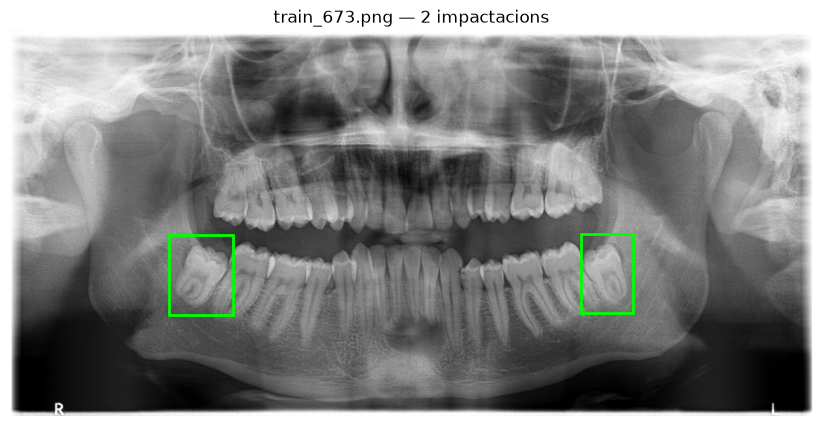

In [5]:
positive_index = next(
    index
    for index in range(len(train_dataset))
    if train_dataset[index][1]["boxes"].shape[0] > 0
)

image, target = train_dataset[positive_index]

figure, axis = plt.subplots(figsize=(16, 5))
axis.imshow(image.permute(1, 2, 0))

for x_min, y_min, x_max, y_max in target["boxes"]:
    axis.add_patch(
        Rectangle(
            (x_min.item(), y_min.item()),
            (x_max - x_min).item(),
            (y_max - y_min).item(),
            edgecolor="lime",
            facecolor="none",
            linewidth=2
        )
    )

axis.set_title(
    f"{train_dataset.file_name(positive_index)} — "
    f"{len(target['boxes'])} impactacions"
)
axis.axis("off")
plt.show()

In [6]:
def collate_fn(batch):
    # Les imatges poden tenir mides diferents i cada imatge
    # pot tenir un nombre diferent de boxes.
    return tuple(zip(*batch))


batch_size = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

images, targets = next(iter(train_loader))
print("Imatges al batch:", len(images))
print("Boxes per imatge:", [len(t["boxes"]) for t in targets])

Imatges al batch: 2
Boxes per imatge: [0, 0]


In [7]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def build_detector(pretrained=True):
    if pretrained:
        model = fasterrcnn_resnet50_fpn(
            weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
            trainable_backbone_layers=3,
            min_size=512,
            max_size=1600
        )
    else:
        # Per reconstruir l'arquitectura abans de carregar el checkpoint.
        model = fasterrcnn_resnet50_fpn(
            weights=None,
            weights_backbone=None,
            min_size=512,
            max_size=1600
        )

    input_features = (
        model.roi_heads.box_predictor.cls_score.in_features
    )

    # Dues classes totals: background + impacted.
    model.roi_heads.box_predictor = FastRCNNPredictor(
        input_features,
        num_classes=2
    )

    return model


detector = build_detector(pretrained=True).to(device)
print("Detector creat.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\Neo-PC/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:03<00:00, 51.3MB/s] 


Detector creat.


In [8]:
# Smoke test: comprovem que una passada d'entrenament produeix losses.
images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

detector.train()

with torch.no_grad():
    loss_dict = detector(images, targets)

print({
    name: round(value.item(), 4)
    for name, value in loss_dict.items()
})

detector.eval()

{'loss_classifier': 0.8049, 'loss_box_reg': 0.0, 'loss_objectness': 0.0066, 'loss_rpn_box_reg': 0.0}


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=1600, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [9]:
def train_one_epoch(model, data_loader, optimizer, device):
    model.train()
    running_loss = 0.0
    n_images = 0

    for images, targets in data_loader:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        loss_dict = model(images, targets)
        total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError(
                f"Loss no finita: {total_loss.item()}"
            )

        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )
        optimizer.step()

        batch_images = len(images)
        running_loss += total_loss.item() * batch_images
        n_images += batch_images

    return running_loss / n_images

In [10]:
from torchvision.ops import box_iou


def match_image_detections(
    predicted_boxes,
    predicted_scores,
    true_boxes,
    score_threshold=0.30,
    iou_threshold=0.50
):
    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    # Ordenem de més a menys confiança.
    order = predicted_scores.argsort(descending=True)
    predicted_boxes = predicted_boxes[order]

    if len(predicted_boxes) == 0:
        return 0, 0, len(true_boxes)

    if len(true_boxes) == 0:
        return 0, len(predicted_boxes), 0

    ious = box_iou(predicted_boxes, true_boxes)
    matched_true_boxes = set()
    true_positives = 0
    false_positives = 0

    for prediction_index in range(len(predicted_boxes)):
        best_iou, true_index = ious[prediction_index].max(dim=0)
        true_index = true_index.item()

        if (
            best_iou.item() >= iou_threshold
            and true_index not in matched_true_boxes
        ):
            true_positives += 1
            matched_true_boxes.add(true_index)
        else:
            false_positives += 1

    false_negatives = len(true_boxes) - len(matched_true_boxes)

    return true_positives, false_positives, false_negatives


@torch.no_grad()
def evaluate_detector(
    model,
    data_loader,
    device,
    score_threshold=0.30,
    iou_threshold=0.50
):
    model.eval()

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, targets in data_loader:
        images_device = [image.to(device) for image in images]
        outputs = model(images_device)

        for output, target in zip(outputs, targets):
            tp, fp, fn = match_image_detections(
                output["boxes"].cpu(),
                output["scores"].cpu(),
                target["boxes"],
                score_threshold=score_threshold,
                iou_threshold=iou_threshold
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0
        else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [11]:
trainable_parameters = [
    parameter
    for parameter in detector.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.SGD(
    trainable_parameters,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

num_epochs = 8
best_f1 = -1.0
checkpoint_path = Path(
    "models/fasterrcnn_impacted_best.pt"
)
checkpoint_path.parent.mkdir(exist_ok=True)

history = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(
        detector,
        train_loader,
        optimizer,
        device
    )

    validation_metrics = evaluate_detector(
        detector,
        val_loader,
        device,
        score_threshold=0.30,
        iou_threshold=0.50
    )

    scheduler.step()

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **validation_metrics
    }
    history.append(epoch_results)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"precision: {validation_metrics['precision']:.3f} | "
        f"recall: {validation_metrics['recall']:.3f} | "
        f"F1: {validation_metrics['f1']:.3f} | "
        f"TP/FP/FN: {validation_metrics['tp']}/"
        f"{validation_metrics['fp']}/"
        f"{validation_metrics['fn']}"
    )

    if validation_metrics["f1"] > best_f1:
        best_f1 = validation_metrics["f1"]

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": detector.state_dict(),
                "metrics": validation_metrics
            },
            checkpoint_path
        )

        print(
            f"  Checkpoint desat amb F1={best_f1:.3f}"
        )

history_df = pd.DataFrame(history)
display(history_df)

Epoch 1/8 | train loss: 0.1304 | precision: 0.317 | recall: 0.950 | F1: 0.475 | TP/FP/FN: 38/82/2
  Checkpoint desat amb F1=0.475
Epoch 2/8 | train loss: 0.0877 | precision: 0.432 | recall: 0.950 | F1: 0.594 | TP/FP/FN: 38/50/2
  Checkpoint desat amb F1=0.594
Epoch 3/8 | train loss: 0.0687 | precision: 0.535 | recall: 0.950 | F1: 0.685 | TP/FP/FN: 38/33/2
  Checkpoint desat amb F1=0.685
Epoch 4/8 | train loss: 0.0499 | precision: 0.654 | recall: 0.850 | F1: 0.739 | TP/FP/FN: 34/18/6
  Checkpoint desat amb F1=0.739
Epoch 5/8 | train loss: 0.0458 | precision: 0.654 | recall: 0.850 | F1: 0.739 | TP/FP/FN: 34/18/6
Epoch 6/8 | train loss: 0.0432 | precision: 0.694 | recall: 0.850 | F1: 0.764 | TP/FP/FN: 34/15/6
  Checkpoint desat amb F1=0.764
Epoch 7/8 | train loss: 0.0405 | precision: 0.694 | recall: 0.850 | F1: 0.764 | TP/FP/FN: 34/15/6
Epoch 8/8 | train loss: 0.0399 | precision: 0.694 | recall: 0.850 | F1: 0.764 | TP/FP/FN: 34/15/6


,epoch,train_loss,tp,fp,fn,precision,recall,f1
0,1,0.130401,38,82,2,0.316667,0.95,0.475000
1,2,0.087750,38,50,2,0.431818,0.95,0.593750
2,3,0.068714,38,33,2,0.535211,0.95,0.684685
3,4,0.049927,34,18,6,0.653846,0.85,0.739130
4,5,0.045764,34,18,6,0.653846,0.85,0.739130
5,6,0.043184,34,15,6,0.693878,0.85,0.764045
6,7,0.040496,34,15,6,0.693878,0.85,0.764045
7,8,0.039903,34,15,6,0.693878,0.85,0.764045


In [12]:
best_detector = build_detector(pretrained=False).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

best_detector.load_state_dict(
    checkpoint["model_state_dict"]
)
best_detector.eval()

print("Millor època:", checkpoint["epoch"])
print("Mètriques desades:", checkpoint["metrics"])

Millor època: 6
Mètriques desades: {'tp': 34, 'fp': 15, 'fn': 6, 'precision': 0.6938775510204082, 'recall': 0.85, 'f1': 0.7640449438202247}


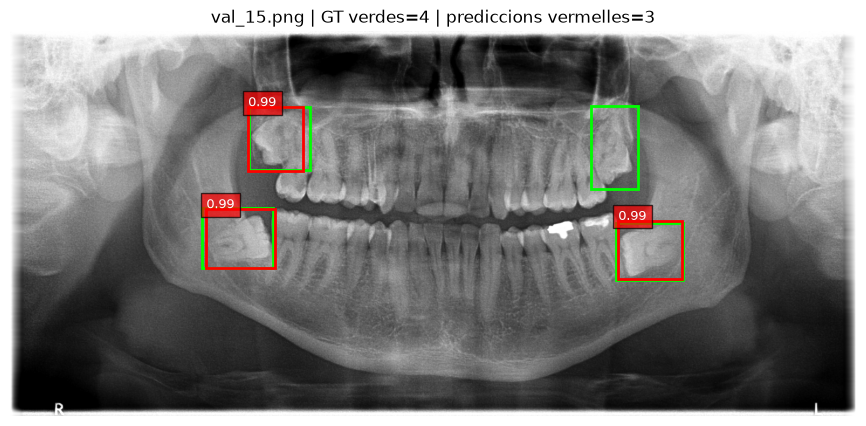

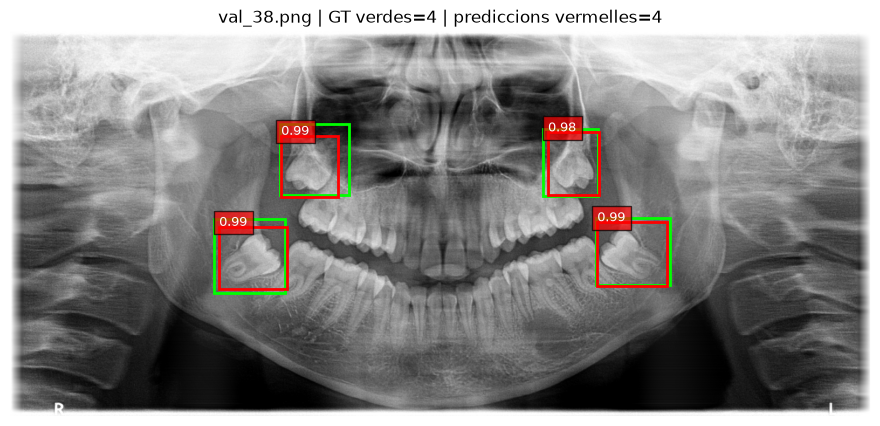

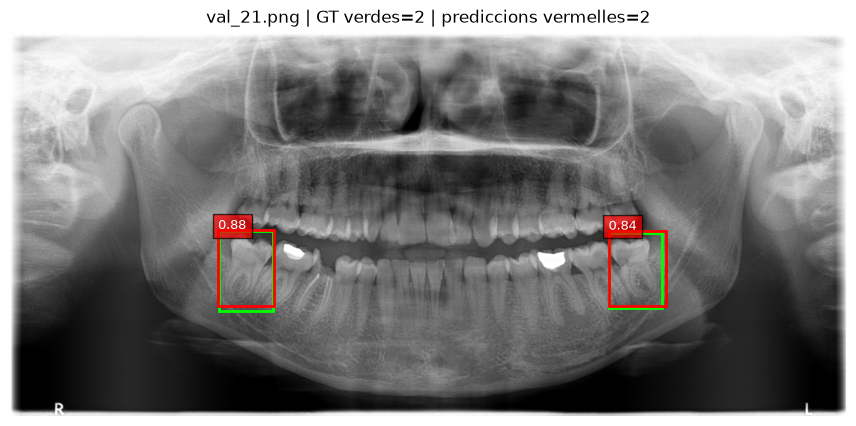

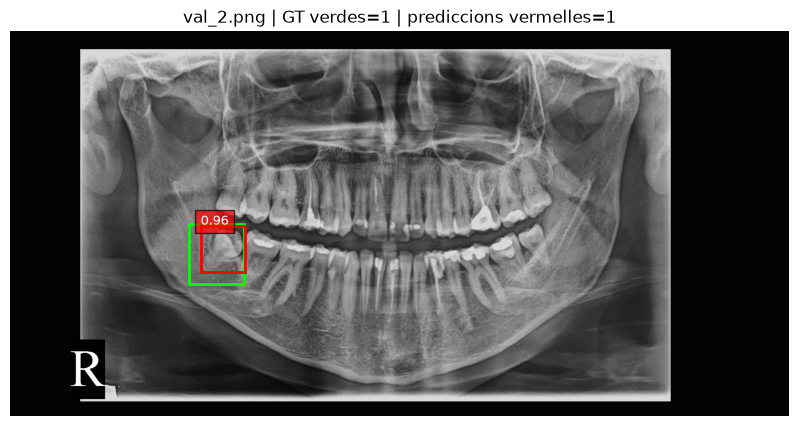

In [13]:
@torch.no_grad()
def show_detector_prediction(
    dataset,
    index,
    model=best_detector,
    score_threshold=0.30
):
    image, target = dataset[index]
    output = model([image.to(device)])[0]

    predicted_boxes = output["boxes"].cpu()
    predicted_scores = output["scores"].cpu()

    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    figure, axis = plt.subplots(figsize=(17, 5))
    axis.imshow(image.permute(1, 2, 0))

    # Ground truth en verd.
    for x_min, y_min, x_max, y_max in target["boxes"]:
        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="lime",
                facecolor="none",
                linewidth=2
            )
        )

    # Prediccions en vermell.
    for box, score in zip(predicted_boxes, predicted_scores):
        x_min, y_min, x_max, y_max = box

        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="red",
                facecolor="none",
                linewidth=2
            )
        )

        axis.text(
            x_min.item(),
            max(0, y_min.item() - 3),
            f"{score.item():.2f}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.7}
        )

    axis.set_title(
        f"{dataset.file_name(index)} | "
        f"GT verdes={len(target['boxes'])} | "
        f"prediccions vermelles={len(predicted_boxes)}"
    )
    axis.axis("off")
    plt.show()


positive_indices = [
    index
    for index in range(len(val_dataset))
    if len(val_dataset[index][1]["boxes"]) > 0
][:4]

for index in positive_indices:
    show_detector_prediction(val_dataset, index)

In [14]:
# El llindar de score modifica el compromís precisió-recall.
threshold_results = []

for score_threshold in [0.20, 0.30, 0.50, 0.70]:
    metrics = evaluate_detector(
        best_detector,
        val_loader,
        device,
        score_threshold=score_threshold,
        iou_threshold=0.50
    )

    threshold_results.append({
        "score_threshold": score_threshold,
        **metrics
    })

display(pd.DataFrame(threshold_results))

,score_threshold,tp,fp,fn,precision,recall,f1
0,0.2,35,15,5,0.700000,0.875,0.777778
1,0.3,34,15,6,0.693878,0.850,0.764045
2,0.5,34,11,6,0.755556,0.850,0.800000
3,0.7,34,10,6,0.772727,0.850,0.809524


## Com interpretar aquest primer detector

- Una predicció és TP si té `IoU >= 0.5` amb una box real encara no assignada.
- `precision` indica quantes boxes predites corresponen a impactacions reals.
- `recall` indica quantes impactacions reals ha trobat.
- Les imatges sense impactacions són necessàries perquè el model aprengui background, encara que no aportin true negatives a les mètriques estàndard de detecció.

Aquest F1 és una mètrica inicial i dependent del llindar; no és encara mAP COCO. Quan el pipeline funcioni, els passos següents seran afegir mAP, revisar les prediccions, ajustar anchors si cal i incorporar augmentacions que transformin alhora imatges i boxes.